<a href="https://colab.research.google.com/github/HowardChen0211/dataManPy/blob/main/ProblemSet_3_4_pandas.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# California Housing Market, 2020-2025

### Research questions
1. Which California counties had the biggest increase in home values from January 2020 to December 2025?

2. Is there a relationship between home-value growth and rent growth across counties?

3. How did home-value growth change when the 30-year mortgage rate increased from below 5% to above 5%?

4. Which California counties have the least affordable homes compared with household income?

5. Did counties with faster population growth also have faster home-value growth?




### Why these data
I use Zillow housing data together with county-level population and labor-market data. Zillow provides data on home values and rents, while the other data provide information about each county.

For PS3, I also add the 30-year mortgage rate from Freddie Mac, median household income and home value from the ACS, and the 2020 population.

Together, these datasets help me understand how housing markets are different across California counties and how housing prices are related to population and economic factors.

### Unit of analysis
California counties (n = 58). County-level datasets are merged on the FIPS code, and the national mortgage rate is merged on month.

## Import Libraries

In [ ]:
import numpy as np
import pandas as pd
import warnings
warnings.filterwarnings('ignore')

#will display all output not just last command
from IPython.core.interactiveshell import InteractiveShell
InteractiveShell.ast_node_interactivity = "all"

import plotly.express as px
import plotly.graph_objects as go # can get convoluted

pd.set_option('display.float_format', '{:.3f}'.format) # Turn off the scientific notation https://medium.com/@amit25173/steps-to-pandas-turn-off-scientific-notation-62c44b86ee24

# ProblemSet 0

## Load the data

In [ ]:
# Zillow Home Value Index (ZHVI)
zhvi = pd.read_csv("https://github.com/HowardChen0211/dataManPy/raw/refs/heads/main/data/County_zhvi_uc_sfrcondo_tier_0.33_0.67_sm_sa_month.csv")

# Zillow Observed Rent Index (ZORI)
zori = pd.read_csv("https://github.com/HowardChen0211/dataManPy/raw/refs/heads/main/data/County_zori_uc_sfrcondomfr_sm_month.csv")

# County population 2025
pop_2025 = pd.read_csv("https://github.com/HowardChen0211/dataManPy/raw/refs/heads/main/data/CA_Population_estimates_2025.csv")

# ACS 2020-2024 5-year: civilian labor force 16 and over,
unemployment = pd.read_csv("https://github.com/HowardChen0211/dataManPy/raw/refs/heads/main/data/CA_UnemploymentRate.csv")

In [ ]:
# take a look about the data (first 5 rows)
zhvi.head()

,RegionID,SizeRank,RegionName,RegionType,StateName,State,Metro,StateCodeFIPS,MunicipalCodeFIPS,2000-01-31,...,2025-11-30,2025-12-31,2026-01-31,2026-02-28,2026-03-31,2026-04-30,2026-05-31,2026-06-30,2026-07-31,2026-08-31
0,3101,0,Los Angeles County,county,CA,CA,"Los Angeles-Long Beach-Anaheim, CA",6,37,210217.606,...,876483.587,880007.554,881688.904,881664.430,879853.110,877155.644,874790.007,872663.237,872220.754,873008.422
1,139,1,Cook County,county,IL,IL,"Chicago-Naperville-Elgin, IL-IN-WI",17,31,152726.258,...,327258.568,328895.004,330363.857,332095.628,333712.156,335053.112,336017.428,337263.419,339162.650,341569.751
2,1090,2,Harris County,county,TX,TX,"Houston-The Woodlands-Sugar Land, TX",48,201,113021.492,...,283353.950,283400.843,283252.913,282917.698,282310.099,281596.697,280609.690,279554.676,278797.692,278517.967
3,2402,3,Maricopa County,county,AZ,AZ,"Phoenix-Mesa-Chandler, AZ",4,13,146106.504,...,459582.164,460367.020,461220.421,461894.031,461740.422,460735.658,459147.558,457589.894,456733.110,456252.051
4,2841,4,San Diego County,county,CA,CA,"San Diego-Chula Vista-Carlsbad, CA",6,73,216416.160,...,925424.341,927598.249,928828.819,929848.898,930228.330,930115.693,929543.266,928860.114,929330.518,930799.655


In [ ]:
# take a look about the data (first 5 rows)
zori.head()

,RegionID,SizeRank,RegionName,RegionType,StateName,State,Metro,StateCodeFIPS,MunicipalCodeFIPS,2015-01-31,...,2025-11-30,2025-12-31,2026-01-31,2026-02-28,2026-03-31,2026-04-30,2026-05-31,2026-06-30,2026-07-31,2026-08-31
0,3101,0,Los Angeles County,county,CA,CA,"Los Angeles-Long Beach-Anaheim, CA",6,37,1691.320,...,2777.262,2768.420,2770.406,2776.600,2788.838,2797.135,2805.344,2809.822,2810.309,2813.614
1,139,1,Cook County,county,IL,IL,"Chicago-Naperville-Elgin, IL-IN-WI",17,31,1413.147,...,2145.212,2143.577,2157.834,2178.380,2204.530,2226.641,2248.019,2265.658,2274.611,2272.117
2,1090,2,Harris County,county,TX,TX,"Houston-The Woodlands-Sugar Land, TX",48,201,1171.144,...,1577.797,1572.948,1571.596,1569.418,1570.920,1573.802,1580.332,1584.251,1586.397,1586.095
3,2402,3,Maricopa County,county,AZ,AZ,"Phoenix-Mesa-Chandler, AZ",4,13,905.494,...,1692.043,1689.654,1690.670,1697.466,1702.306,1706.189,1711.234,1712.111,1715.836,1716.663
4,2841,4,San Diego County,county,CA,CA,"San Diego-Chula Vista-Carlsbad, CA",6,73,1628.319,...,2917.657,2912.131,2915.513,2929.541,2941.689,2951.787,2963.444,2976.321,2984.436,2993.632


In [ ]:
# take a look about the data (first 5 rows)
pop_2025.head()

,FIPS Code,Summary Level,Area Name,Qualified Area Name,"Total Population (July 1, 2025)"
0,Geo_FIPS,_geo_level_,Geo_NAME,Geo_qname,ORG_T007_001
1,06001,SL050,Alameda County,"Alameda County, California",1636630
2,06003,SL050,Alpine County,"Alpine County, California",1043
3,06005,SL050,Amador County,"Amador County, California",41876
4,06007,SL050,Butte County,"Butte County, California",209211


In [ ]:
# take a look about the data (first 5 rows)
unemployment.head()

,FIPS,GeoLevel,NAME,Qualified Area Name,Area (Land),Area (Water),Civilian Population in Labor Force 16 Years and Over,Civilian Population in Labor Force 16 Years and Over: Employed,Civilian Population in Labor Force 16 Years and Over: Unemployed
0,Geo_FIPS,_geo_level_,Geo_NAME,Geo_qname,Geo_AREALAND,Geo_AREAWATER,SE_A17005_001,SE_A17005_002,SE_A17005_003
1,06001,SL050,"Alameda County, California","Alameda County, California",1910010500,216909647,908995,860129,48866
2,06003,SL050,"Alpine County, California","Alpine County, California",1912292607,12557304,837,800,37
3,06005,SL050,"Amador County, California","Amador County, California",1539967082,29437117,17257,16325,932
4,06007,SL050,"Butte County, California","Butte County, California",4238545149,105204062,100743,93228,7515


**Interpretation**: Both Zillow files are national and wide, with one row per U.S. county and one column per month, so I have to filter to California and reshape them before doing anything else.

# ProblemSet 1

#### Data Inspection

In [ ]:
# prints information about a DataFrame
print(zhvi.info(), "\n")
print(zori.info(), "\n")
print(pop_2025.info(), "\n")
print(unemployment.info(), "\n")

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3071 entries, 0 to 3070
Columns: 329 entries, RegionID to 2026-08-31
dtypes: float64(320), int64(4), object(5)
memory usage: 7.7+ MB
None 

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1407 entries, 0 to 1406
Columns: 149 entries, RegionID to 2026-08-31
dtypes: float64(140), int64(4), object(5)
memory usage: 1.6+ MB
None 

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 59 entries, 0 to 58
Data columns (total 5 columns):
 #   Column                           Non-Null Count  Dtype 
---  ------                           --------------  ----- 
 0   FIPS Code                        59 non-null     object
 1   Summary Level                    59 non-null     object
 2   Area Name                        59 non-null     object
 3   Qualified Area Name              59 non-null     object
 4   Total Population (July 1, 2025)  59 non-null     object
dtypes: object(5)
memory usage: 2.4+ KB
None 

<class 'pandas.core.frame.DataFrame'>
RangeI

In [ ]:
# See how many columns in the data
print("Home Index: ", len(zhvi.columns))
print("Rent Index: ", len(zori.columns))
print("Population: ", len(pop_2025.columns))
print("Unemployment: ", len(unemployment.columns))

Home Index:  329
Rent Index:  149
Population:  5
Unemployment:  9


In [ ]:
# See how big the data
print(zhvi.shape) # (3071, 329)
print(zori.shape) # (1407, 149)
print(pop_2025.shape) # (59, 5)
print(unemployment.shape) # (59, 9)

(3071, 329)
(1407, 149)
(59, 5)
(59, 9)


In [ ]:
# Missing values
print(zhvi.isna().sum().sum())
print()
print(zori.isna().sum().sum())
print()
print(pop_2025.isna().sum().sum())
print()
print(unemployment.isna().sum().sum())

275007

102547

0

0


In [ ]:
# Check Duplicates
print(zhvi.duplicated().sum())
print(zori.duplicated().sum())
print(pop_2025.duplicated().sum())
print(unemployment.duplicated().sum())

0
0
0
0


**Interpretation**: The population and unemployment files have 59 rows, which is the 58 counties plus one code row at the top. Both Zillow files have many missing values, mostly because some counties start later than others. None of the four files has duplicate rows.

#### Data Cleaning

Transform both zillow dataset into long format *ZHVI* & *ZORI* and filtered the dates to include only records from 2020 to 2025.

In [ ]:
START, END = "2020-01", "2026-01"

def zillow_to_long(data, value_name, start=START, end=END):

    cols = ["RegionID", "SizeRank", "RegionName", "RegionType", "StateName", "StateCodeFIPS", "MunicipalCodeFIPS"]
    dates = [i for i in data.columns if i[0].isdigit() and start <= i < end]

    ca = data.loc[data["StateName"] == "CA", cols + dates].copy()
    # FIPS codes is 00+000
    ca["FIPS"] = (ca["StateCodeFIPS"].astype(str).str.zfill(2)
                  + ca["MunicipalCodeFIPS"].astype(str).str.zfill(3))

    ca["RegionName"] = ca["RegionName"].str.strip()

    # wide to long https://pandas.pydata.org/docs/reference/api/pandas.melt.html
    df = ca.melt(id_vars=["FIPS", "RegionName"], value_vars=dates,
                   var_name="Date", value_name=value_name)

    df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

    return df.sort_values(["FIPS", "Date"]).reset_index(drop=True)

# Call the function
zhvi_CA = zillow_to_long(zhvi, "ZHVI")
zori_CA = zillow_to_long(zori, "ZORI")

# See the shape & check unique values
print("ZHVI:", zhvi_CA.shape, "| counties:", zhvi_CA["FIPS"].nunique(), "| months:", zhvi_CA["Date"].nunique())
print("ZORI:", zori_CA.shape, "| counties:", zori_CA["FIPS"].nunique(), "| months:", zori_CA["Date"].nunique())

ZHVI: (4176, 4) | counties: 58 | months: 72
ZORI: (3528, 4) | counties: 49 | months: 72


ZHVI covers all 58 counties × 72 months = 4,176 rows. ZORI has fewer counties because Zillow does not publish rents for some small rural counties.

In [ ]:
# See the data types in the dataframe
zhvi_CA.dtypes

,0
FIPS,object
RegionName,object
Date,datetime64[ns]
ZHVI,float64


In [ ]:
zori_CA.dtypes

,0
FIPS,object
RegionName,object
Date,datetime64[ns]
ZORI,float64


In [ ]:
zhvi_CA.head()

,FIPS,RegionName,Date,ZHVI
0,06001,Alameda County,2020-01-31,842261.950
1,06001,Alameda County,2020-02-29,845568.279
2,06001,Alameda County,2020-03-31,849961.749
3,06001,Alameda County,2020-04-30,854051.748
4,06001,Alameda County,2020-05-31,853204.560


In [ ]:
zori_CA.head()

,FIPS,RegionName,Date,ZORI
0,06001,Alameda County,2020-01-31,2547.423
1,06001,Alameda County,2020-02-29,2548.081
2,06001,Alameda County,2020-03-31,2563.948
3,06001,Alameda County,2020-04-30,2561.371
4,06001,Alameda County,2020-05-31,2556.497


### Data Manipulation

#### Merge 1: ZHVI x ZORI housing

In [ ]:
housing = zhvi_CA.merge(
    zori_CA.drop(columns="RegionName"),
    on=["FIPS", "Date"],
    how="outer",            # keep every county-month that has a home value
    validate="1:1",
    indicator=True,
)

In [ ]:
housing.query("_merge == 'left_only'")

,FIPS,RegionName,Date,ZHVI,ZORI,_merge
72,06003,Alpine County,2020-01-31,389374.972,NaN,left_only
73,06003,Alpine County,2020-02-29,389221.795,NaN,left_only
74,06003,Alpine County,2020-03-31,388438.388,NaN,left_only
75,06003,Alpine County,2020-04-30,388918.625,NaN,left_only
76,06003,Alpine County,2020-05-31,389024.193,NaN,left_only
...,...,...,...,...,...,...
3811,06105,Trinity County,2025-08-31,263132.164,NaN,left_only
3812,06105,Trinity County,2025-09-30,262568.495,NaN,left_only
3813,06105,Trinity County,2025-10-31,261993.268,NaN,left_only
3814,06105,Trinity County,2025-11-30,261540.047,NaN,left_only


In [ ]:
# checks
print(housing["_merge"].value_counts(), "\n")

_merge
both          3528
left_only      648
right_only       0
Name: count, dtype: int64 



In [ ]:
no_rent = sorted(housing.loc[housing["_merge"] == "left_only", "RegionName"].unique())
print(f"{len(no_rent)} counties have no ZORI in any month:\n", no_rent)
housing = housing.drop(columns="_merge")

9 counties have no ZORI in any month:
 ['Alpine County', 'Colusa County', 'Lassen County', 'Mariposa County', 'Modoc County', 'Mono County', 'Plumas County', 'Sierra County', 'Trinity County']


**Interpretation**: The outer join keeps all 4,176 county-months (58 x 72), so no home-value observation is lost. The 648 `left_only` rows are the 9 counties Zillow does not publish rents for at all (Alpine, Colusa, Lassen, Mariposa, Modoc, Mono, Plumas, Sierra, Trinity): small rural counties with few rental listings for a stable index. That is expected and is not a merge error.

#### Merge 2: Unemployment x Population

#### Population (from Social Explorer)

In [ ]:
pop_2025.head()

,FIPS Code,Summary Level,Area Name,Qualified Area Name,"Total Population (July 1, 2025)"
0,Geo_FIPS,_geo_level_,Geo_NAME,Geo_qname,ORG_T007_001
1,06001,SL050,Alameda County,"Alameda County, California",1636630
2,06003,SL050,Alpine County,"Alpine County, California",1043
3,06005,SL050,Amador County,"Amador County, California",41876
4,06007,SL050,Butte County,"Butte County, California",209211


In [ ]:
pop_2025.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 59 entries, 0 to 58
Data columns (total 5 columns):
 #   Column                           Non-Null Count  Dtype 
---  ------                           --------------  ----- 
 0   FIPS Code                        59 non-null     object
 1   Summary Level                    59 non-null     object
 2   Area Name                        59 non-null     object
 3   Qualified Area Name              59 non-null     object
 4   Total Population (July 1, 2025)  59 non-null     object
dtypes: object(5)
memory usage: 2.4+ KB


In [ ]:
pop_2025 = (pop_2025.iloc[1:,:][["FIPS Code", "Area Name", "Total Population (July 1, 2025)"]].rename(columns={"FIPS Code": "FIPS", "Area Name": "County", "Total Population (July 1, 2025)": "pop_2025"}))

pop_2025["pop_2025"] = pop_2025["pop_2025"].astype(int)

print(pop_2025.shape)
pop_2025.head()

(58, 3)


,FIPS,County,pop_2025
1,06001,Alameda County,1636630
2,06003,Alpine County,1043
3,06005,Amador County,41876
4,06007,Butte County,209211
5,06009,Calaveras County,46605


#### Unemployment (ACS 2020–2024 5-year Estimates)

In [ ]:
# row 0 holds the (Geo_FIPS, SE_A17005_001, ...), so drop it
unemployment = (unemployment
                .loc[1:, ["FIPS", "NAME",
                          "Civilian Population in Labor Force 16 Years and Over",
                          "Civilian Population in Labor Force 16 Years and Over: Unemployed"]]
                .rename(columns={"NAME": "County",
                                 "Civilian Population in Labor Force 16 Years and Over": "labor_force",
                                 "Civilian Population in Labor Force 16 Years and Over: Unemployed": "unemployed"}))

unemployment["County"] = unemployment["County"].str.replace(", California", "")

unemployment["FIPS"] = unemployment["FIPS"].astype(str).str.zfill(5)

unemployment[["labor_force", "unemployed"]] = unemployment[["labor_force", "unemployed"]].astype(int)

unemployment["unemp_rate"] = unemployment["unemployed"] / unemployment["labor_force"] * 100

print(unemployment.shape)

unemployment.head(3)

(58, 5)


,FIPS,County,labor_force,unemployed,unemp_rate
1,06001,Alameda County,908995,48866,5.376
2,06003,Alpine County,837,37,4.421
3,06005,Amador County,17257,932,5.401


In [ ]:
labor = unemployment.merge(pop_2025.drop(columns="County"), on="FIPS",
                           how="outer", validate="1:1", indicator=True)

print(labor["_merge"].value_counts())

labor = labor.drop(columns="_merge")

labor.head()

_merge
both          58
left_only      0
right_only     0
Name: count, dtype: int64


,FIPS,County,labor_force,unemployed,unemp_rate,pop_2025
0,06001,Alameda County,908995,48866,5.376,1636630
1,06003,Alpine County,837,37,4.421,1043
2,06005,Amador County,17257,932,5.401,41876
3,06007,Butte County,100743,7515,7.460,209211
4,06009,Calaveras County,19422,877,4.515,46605


**Interpretation**: All 58 counties matched on both sides, with no `left_only` or `right_only` rows. That's what I expected, since both files are Social Explorer exports for the same list of California counties and FIPS is kept as a 5-digit string in both.

In [ ]:
labor.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 58 entries, 0 to 57
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   FIPS         58 non-null     object 
 1   County       58 non-null     object 
 2   labor_force  58 non-null     int64  
 3   unemployed   58 non-null     int64  
 4   unemp_rate   58 non-null     float64
 5   pop_2025     58 non-null     int64  
dtypes: float64(1), int64(3), object(2)
memory usage: 2.8+ KB


## Mapping: 1. Counties to Regions
Group into Six Regions

Source: https://coolcalifornia.arb.ca.gov/regions

In [ ]:
regions = {
    "Bay Area": ["Alameda", "Contra Costa", "Marin", "Napa", "San Francisco",
                 "San Mateo", "Santa Clara", "Solano", "Sonoma"],
    "Southern California": ["Imperial", "Los Angeles", "Orange", "Riverside",
                            "San Bernardino", "San Diego", "Ventura"],
    "Central Coast": ["Monterey", "San Benito", "San Luis Obispo", "Santa Barbara", "Santa Cruz"],
    "Central Valley": ["Butte", "Colusa", "Fresno", "Glenn", "Kern", "Kings", "Madera",
                       "Merced", "Sacramento", "San Joaquin", "Stanislaus", "Sutter",
                       "Tehama", "Tulare", "Yolo", "Yuba"],
    "Sierra / Gold Country": ["Alpine", "Amador", "Calaveras", "El Dorado", "Inyo",
                              "Mariposa", "Mono", "Nevada", "Placer", "Plumas",
                              "Sierra", "Tuolumne"],
    "North Coast / Far North": ["Del Norte", "Humboldt", "Lake", "Lassen", "Mendocino",
                                "Modoc", "Shasta", "Siskiyou", "Trinity"],
}

county_to_region = {}

for region, county in regions.items():
  for c in county:
    county_to_region[f"{c} County"] = region

housing["region"] = housing["RegionName"].map(county_to_region)

housing.drop_duplicates("FIPS")["region"].value_counts() # Total should be 58

,count
region,
Central Valley,16
Sierra / Gold Country,12
Bay Area,9
North Coast / Far North,9
Southern California,7
Central Coast,5


**Interpretation**: Every county got a region, since the counts add up to 58 and nothing was left. The groups are pretty uneven, the Central Valley has 16 counties and the Central Coast only 5, so the averages for the smaller regions rest on just a handful of places.

## Mapping 2: population to county size

In [ ]:
labor["size_tier"] = pd.cut(labor["pop_2025"],
                            bins=[0, 100_000, 1_000_000, np.inf],
                            labels=["Small (<100k)", "Mid (100k-1M)", "Large (1M+)"])
labor["size_tier"].value_counts().sort_index()

,count
size_tier,
Small (<100k),22
Mid (100k-1M),26
Large (1M+),10


**Interpretation**: Most California counties are small or mid-sized, and only 10 of the 58 have more than a million people. The 100k and 1M cutoffs are my own round numbers rather than an official definition, but they're easy to explain and leave each group with a reasonable number of counties.

# ProblemSet 2

#### Groupby/Agg 1: County-level housing growth

I first aggregate the monthly Zillow data to the county level. This allows me to compare home values and rents at the beginning.

**!!! Note: I filtered the county that only has the complete 72 months of ZORI data, so that I can compare !!!!**

In [ ]:
housing_full_zori_county = housing[~housing["ZORI"].isna()]

housing_full_zori_county = housing_full_zori_county.groupby(["FIPS", "RegionName"]).agg(months=("Date", "nunique"))

# This line of code I'm using Gemini to help me how to get the values from index
housing_full_zori_county = housing_full_zori_county[housing_full_zori_county["months"] == 72].index.get_level_values('RegionName').unique().to_list()

In [ ]:
len(housing_full_zori_county)

29

**Interpretation**: Only 29 of the 58 counties have rent data for all 72 months, so the rent-versus-home-value comparison is based on these 29. Most of the dropped counties are small rural ones whose ZORI series starts late or doesn't exist at all.

In [ ]:
housings = housing[housing["RegionName"].isin(housing_full_zori_county)].reset_index(drop=True)

##### RQ1: Which California counties saw the fastest growth in home values from 2020 to 2025?

In [ ]:
# Group monthly housing data by county
county_housing = (
    housings
    .sort_values(["FIPS", "Date"])
    .groupby(["FIPS", "RegionName"])
    .agg(
        zhvi_2020=("ZHVI", "first"),
        zhvi_2025=("ZHVI", "last"),
        zori_2020=("ZORI", "first"),
        zori_2025=("ZORI", "last"),
        months=("Date", "nunique")
    ).reset_index())

# Calculate percentage growth
county_housing["zhvi_growth_pct"] = ((county_housing["zhvi_2025"] - county_housing["zhvi_2020"])
                                      / county_housing["zhvi_2020"] * 100)

county_housing["zori_growth_pct"] = ((county_housing["zori_2025"] - county_housing["zori_2020"])
                                      / county_housing["zori_2020"] * 100)

county_housing.sort_values("zhvi_growth_pct", ascending=False).reset_index(drop=True).head(10)

,FIPS,RegionName,zhvi_2020,zhvi_2025,zori_2020,zori_2025,months,zhvi_growth_pct,zori_growth_pct
0,06083,Santa Barbara County,604363.958,970185.816,2111.031,3125.583,72,60.530,48.060
1,06029,Kern County,236887.162,362888.534,1139.586,1730.258,72,53.190,51.832
2,06073,San Diego County,606555.564,927598.249,2082.318,2912.131,72,52.929,39.850
3,06065,Riverside County,402042.996,605008.058,1740.369,2554.693,72,50.483,46.790
4,06071,San Bernardino County,369240.934,547407.809,1648.598,2412.321,72,48.252,46.326
5,06107,Tulare County,242725.451,358608.931,1124.410,1690.461,72,47.743,50.342
6,06019,Fresno County,278536.136,405709.400,1342.323,1988.009,72,45.658,48.102
7,06079,San Luis Obispo County,617020.411,891942.555,1955.495,2780.955,72,44.556,42.212
8,06085,Santa Clara County,1125886.109,1608192.584,3064.590,3540.084,72,42.838,15.516
9,06047,Merced County,295777.004,418573.042,1337.669,1995.053,72,41.516,49.144


**Interpretation**: Santa Barbara leads at 60.5%, followed by Kern, San Diego, and Riverside, all above 50%. What stands out is how many cheaper inland counties make the top ten (Kern, Tulare, Fresno, Merced), and in those places rents grew about as fast as home values, roughly 48–52%. Santa Clara is the odd one out: home values rose 43% but rent only 16%.

**Note: this ranking only includes the 29 counties with full rent data. The full ranking of all 58 counties is in the PS3 & 4 section, where Orange County (59.8%) ranks second.**

##### RQ2: To what extent is home-value growth associated with rent growth across counties? (Only 29 Counties compared)

In [ ]:
print("correlation:", round(county_housing["zhvi_growth_pct"].corr(county_housing["zori_growth_pct"]), 2))

correlation: 0.72


**Interpretation:** Across the 29 counties, home-value growth and rent growth are strongly related (correlation 0.72). Counties where home values grew faster usually also had faster rent growth. Santa Clara is the main exception: home values rose 43%, but rent rose only 16%.

#### Groupby/Agg 2: Regional housing market (58 Counties)

Next, I aggregate the county-level housing data by region. This makes it possible to compare broader geographic housing-market patterns rather than looking only at individual counties.

In [ ]:
# Group monthly housing data by county
county_housing = (
    housing
    .sort_values(["FIPS", "Date"])
    .groupby(["FIPS", "RegionName"])
    .agg(
        zhvi_2020=("ZHVI", "first"),
        zhvi_2025=("ZHVI", "last"),
        months=("Date", "nunique")
    ).reset_index())

# Calculate percentage growth
county_housing["zhvi_growth_pct"] = ((county_housing["zhvi_2025"] - county_housing["zhvi_2020"])
                                      / county_housing["zhvi_2020"] * 100)

In [ ]:
# Add the regional classification
county_housing["region"] = county_housing["RegionName"].map(county_to_region)

regional_housing = (county_housing.groupby("region").agg(
        avg_zhvi_growth=("zhvi_growth_pct", "mean"),
        counties=("FIPS", "nunique")
    ).reset_index().sort_values("avg_zhvi_growth", ascending=False)
)

regional_housing

,region,avg_zhvi_growth,counties
5,Southern California,48.236,7
1,Central Coast,41.956,5
2,Central Valley,37.704,16
4,Sierra / Gold Country,30.794,12
0,Bay Area,22.387,9
3,North Coast / Far North,17.293,9


**Interpretation**: Southern California grew the fastest (48.2% on average), followed by the Central Coast (42.0%) and the Central Valley (37.7%). The Bay Area (22.4%) and the North Coast (17.3%) grew the slowest. Some regions have only a few counties (the Central Coast has 5), so these averages should be read with caution.

#### Recode 1: Categorizing home-value growth

To make differences in housing growth easier to compare, I recode the continuous home-value growth measure into three categories.

This classification distinguishes counties with relatively low, moderate, and high home-value growth.

In [ ]:
# Use the 33rd and 67th percentiles to define relative growth categories
low_cutoff = county_housing["zhvi_growth_pct"].quantile(1/3)
high_cutoff = county_housing["zhvi_growth_pct"].quantile(2/3)

county_housing["growth_category"] = pd.cut(
    county_housing["zhvi_growth_pct"],
    bins=[-np.inf, low_cutoff, high_cutoff, np.inf],
    labels=["Low growth", "Medium growth", "High growth"]
)

county_housing["growth_category"].value_counts().sort_index()

,count
growth_category,
Low growth,19
Medium growth,20
High growth,19


**Interpretation**: The 33rd/67th percentile cutoffs split the 58 counties into three almost equal groups (19, 20, and 19). The groups are relative, so "Low growth" doesn't mean prices fell.

### Replace on Condition 1: Categorize unemployment conditions

I classify counties according to their unemployment rate. This allows me to compare housing growth across counties with different labor-market conditions.

In [ ]:
labor["unemployment_status"] = "Low unemployment"

labor.loc[labor["unemp_rate"] >= 5, "unemployment_status"] = "Moderate unemployment"

labor.loc[labor["unemp_rate"] >= 8, "unemployment_status"] = "High unemployment"

labor[["County", "unemp_rate", "labor_force", "unemployment_status"]].sort_values("unemp_rate", ascending=False).head()

,County,unemp_rate,labor_force,unemployment_status
45,Sierra County,12.631,1243,High unemployment
12,Imperial County,12.522,71192,High unemployment
16,Lake County,11.058,28259,High unemployment
15,Kings County,10.803,60047,High unemployment
23,Merced County,10.557,128465,High unemployment


Sierra County tops the list at 12.6%, but its labor force is only about 1,200 people, so a handful of job losses can move its rate a lot.

### Subset 1: Large California counties

I also create a subset of large counties to examine whether housing-market patterns among the largest population centers differ from the statewide county-level pattern.

In [ ]:
large_counties = labor[labor["size_tier"] == "Large (1M+)"].copy()

large_counties[["FIPS", "County", "pop_2025", "unemp_rate", "size_tier"]].sort_values("pop_2025", ascending=False)

total_pop = labor["pop_2025"].sum()
ten_counties_pop = large_counties["pop_2025"].sum()
percent = ten_counties_pop / total_pop
print(f"10 largest counties: {ten_counties_pop:,} of {total_pop:,} people ({percent:.1%})")

,FIPS,County,pop_2025,unemp_rate,size_tier
18,06037,Los Angeles County,9694934,7.271,Large (1M+)
36,06073,San Diego County,3282248,6.110,Large (1M+)
29,06059,Orange County,3149507,5.404,Large (1M+)
32,06065,Riverside County,2544916,6.501,Large (1M+)
35,06071,San Bernardino County,2224091,7.109,Large (1M+)
42,06085,Santa Clara County,1914391,4.867,Large (1M+)
0,06001,Alameda County,1636630,5.376,Large (1M+)
33,06067,Sacramento County,1618460,6.712,Large (1M+)
6,06013,Contra Costa County,1170070,6.490,Large (1M+)
9,06019,Fresno County,1035456,8.693,Large (1M+)


10 largest counties: 28,270,703 of 39,355,309 people (71.8%)


**Interpretation**: These ten counties hold about 72% of California's population, so these counties cover most of the people in the state. Fresno is the only one above 8% unemployment and Santa Clara the only one below 5%, so even the biggest counties face pretty different labor markets.

# ProblemSet 3 & 4


### Home-value for all 58 counties

PS2 cut `housing` to 29 counties only because of the rent data, so here I go back to all 58. Year-over-year growth needs the same month one year earlier, and `zhvi_CA` from PS1 starts in 2020, so I reload ZHVI from January 2019, compute YoY for each county, and then keep 2020–2025.

In [ ]:
zhvi_CA = zillow_to_long(zhvi, "ZHVI", "2019-01", "2026-01")

print(zhvi_CA.shape, "| counties:", zhvi_CA["FIPS"].nunique(), "| months:", zhvi_CA["Date"].nunique())

(4872, 4) | counties: 58 | months: 84


In [ ]:
home = zhvi_CA.copy()

home["region"] = home["RegionName"].map(county_to_region)
home["ym"] = home["Date"].dt.to_period("M") # month key for the merges

# year-over-year growth
home = home.sort_values(["FIPS", "Date"]).reset_index(drop=True)
home["zhvi_yoy"] = home.groupby("FIPS")["ZHVI"].pct_change(12, fill_method=None) * 100

# Keep only the original PS3 analysis period: 2020–2025.
home = home.loc[home["Date"] >= "2020-01"].reset_index(drop=True)

print(home.shape, "| counties:", home["FIPS"].nunique(), "| months:", home["ym"].nunique())
print("missing ZHVI:", home["ZHVI"].isna().sum(), "| missing YoY:", home["zhvi_yoy"].isna().sum())

# which rows have no YoY value?
home.loc[home["zhvi_yoy"].isna(), ["FIPS", "RegionName", "Date", "ZHVI", "zhvi_yoy"]]

(4176, 7) | counties: 58 | months: 72
missing ZHVI: 2 | missing YoY: 4


,FIPS,RegionName,Date,ZHVI,zhvi_yoy
1520,06043,Mariposa County,2020-09-30,NaN,NaN
1521,06043,Mariposa County,2020-10-31,NaN,NaN
1532,06043,Mariposa County,2021-09-30,411389.324,NaN
1533,06043,Mariposa County,2021-10-31,412199.584,NaN


**Interpretation**: Only four growth values are missing and all four are Mariposa. Zillow has no home value for Mariposa in September and October 2020, so those two months have no growth, and September and October 2021 have nothing one year earlier to compare.

## Mortgage Rate 30-years

30-Year Fixed Rate Mortgage Average in the United States, from Freddie Mac's weekly Primary Mortgage Market Survey.

Source: https://fred.stlouisfed.org/series/MORTGAGE30US

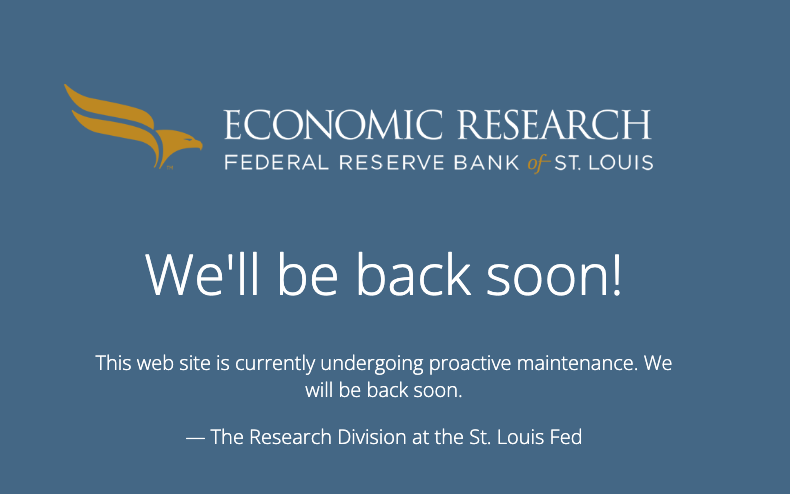

The API call failed because the website is down for maintenance.

In [ ]:
# import datetime
# import pandas_datareader as pdr

# start = datetime.datetime(2019, 1, 1)
# end = datetime.datetime(2025, 12, 31)

# # Freddie Mac PMMS 30-year fixed rate, weekly
# mortgage_raw = pdr.DataReader('MORTGAGE30US', 'fred', start, end) # MORTGAGE30US is the code for series: know it from fed's url: https://fred.stlouisfed.org/series/MORTGAGE30US

### Load the data

In [ ]:
import datetime
import pandas as pd

# Fetch FRED data
mortgage_raw = pd.read_csv("https://github.com/HowardChen0211/dataManPy/raw/refs/heads/main/data/MORTGAGE30US.csv")

print(mortgage_raw.shape)
print("missing:", mortgage_raw.isna().sum().sum(), "| duplicate dates:", mortgage_raw.index.duplicated().sum())

mortgage_raw

(366, 2)
missing: 0 | duplicate dates: 0


,observation_date,MORTGAGE30US
0,2019-01-03,4.510
1,2019-01-10,4.450
2,2019-01-17,4.450
3,2019-01-24,4.450
4,2019-01-31,4.460
...,...,...
361,2025-12-04,6.190
362,2025-12-11,6.220
363,2025-12-18,6.210
364,2025-12-24,6.180


In [ ]:
mortgage = (
    mortgage_raw
    .reset_index()
    .rename(columns={"observation_date": "week", "MORTGAGE30US": "rate30"})
)

mortgage["week"] = pd.to_datetime(mortgage["week"])
mortgage["rate30"] = pd.to_numeric(mortgage["rate30"], errors="coerce")

print(mortgage.shape, "| missing rates:", mortgage["rate30"].isna().sum())
print("duplicate weeks:", mortgage["week"].duplicated().sum())

# PMMS is released on Thursdays, except some holiday weeks
mortgage["week"].dt.day_name().value_counts()

(366, 3) | missing rates: 0
duplicate weeks: 0


,count
week,
Thursday,353
Wednesday,13


**Interpretation**: 353 of the 366 weekly falls on a Thursday and the other 13 on a Wednesday. Those are holiday weeks when Freddie Mac released a day early, which is one more reason not to match on the exact date.

### Weekly to monthly

Zillow is monthly, so I average the 4-5 weekly observations in each month.

I also build two variables: the 12-month change in the rate, and a recode into a low-rate vs. high-rate regime.

In [ ]:
mortgage_m = (mortgage
              .assign(mth = mortgage["week"].dt.to_period("M"))
              .groupby("mth", as_index=False)
              .agg(rate30=("rate30", "mean"),
                   n_weeks=("rate30", "count")))

# change vs. same month last year, in percentage points
mortgage_m["rate30_chg12"] = mortgage_m["rate30"] - mortgage_m["rate30"].shift(12)

# regime recode
mortgage_m["rate_regime"] = "Low rate (<5%)"
mortgage_m.loc[mortgage_m["rate30"] >= 5, "rate_regime"] = "High rate (5%+)"


print(mortgage_m.shape) # expect 84 months = 7 years x 12

# first and last month of each regime
mortgage_m.groupby("rate_regime").agg(months=("mth", "count"), first_month=("mth", "min"), last_month=("mth", "max"))

(84, 5)


,months,first_month,last_month
rate_regime,,,
High rate (5%+),44,2022-05,2025-12
Low rate (<5%),40,2019-01,2022-04


**Interpretation**: There are 84 months because I kept 2019 for the 12-month change. The rate was under 5% for 40 months in a row, from January 2019 to April 2022, and it has been at 5% or more in all 44 months since May 2022. So the recode splits the period cleanly into a before and an after, with no going back and forth.

In [ ]:
home_rate = home.merge(
    mortgage_m,
    left_on="ym",
    right_on="mth",
    how="outer",          # outer on purpose to see what doesn't match
    validate="m:1",       # many county-months to one national rate per month
    indicator=True,
)

home_rate["_merge"].value_counts()

# crosstab the merge result
pd.crosstab(home_rate["mth"].dt.year, home_rate["_merge"])

,count
_merge,
both,4176
right_only,12
left_only,0


_merge,right_only,both
mth,,
2019,12,0
2020,0,696
2021,0,696
2022,0,696
2023,0,696
2024,0,696
2025,0,696


**Interpretation**: Every county-month found a rate (696 per year = 58 × 12), so nothing on the housing side is lost. The 12 `right_only` rows are the 2019 months that I kept only for the 12-month change, and the Zillow data starts in 2020, so they're expected.

In [ ]:
# keep the matched rows
home_rate = (home_rate[home_rate["_merge"] == "both"]
             .drop(columns=["_merge", "n_weeks"])
             .reset_index(drop=True))

home_rate.head(10)

,FIPS,RegionName,Date,ZHVI,region,ym,zhvi_yoy,mth,rate30,rate30_chg12,rate_regime
0,06001,Alameda County,2020-01-31,842261.950,Bay Area,2020-01,-1.179,2020-01,3.624,-0.840,Low rate (<5%)
1,06003,Alpine County,2020-01-31,389374.972,Sierra / Gold Country,2020-01,1.952,2020-01,3.624,-0.840,Low rate (<5%)
2,06005,Amador County,2020-01-31,348422.225,Sierra / Gold Country,2020-01,2.342,2020-01,3.624,-0.840,Low rate (<5%)
3,06007,Butte County,2020-01-31,342651.808,Central Valley,2020-01,11.982,2020-01,3.624,-0.840,Low rate (<5%)
4,06009,Calaveras County,2020-01-31,335227.783,Sierra / Gold Country,2020-01,3.384,2020-01,3.624,-0.840,Low rate (<5%)
5,06011,Colusa County,2020-01-31,280035.397,Central Valley,2020-01,6.582,2020-01,3.624,-0.840,Low rate (<5%)
6,06013,Contra Costa County,2020-01-31,633890.619,Bay Area,2020-01,1.348,2020-01,3.624,-0.840,Low rate (<5%)
7,06015,Del Norte County,2020-01-31,285427.254,North Coast / Far North,2020-01,7.917,2020-01,3.624,-0.840,Low rate (<5%)
8,06017,El Dorado County,2020-01-31,501335.947,Sierra / Gold Country,2020-01,2.416,2020-01,3.624,-0.840,Low rate (<5%)
9,06019,Fresno County,2020-01-31,278536.136,Central Valley,2020-01,4.396,2020-01,3.624,-0.840,Low rate (<5%)


### RQ3: housing-value growth vs. the mortgage rate
How did home-value growth change when the 30-year mortgage rate increased from below 5% to above 5%?


In [ ]:
import plotly.graph_objects as go
from plotly.subplots import make_subplots

state_month = (home_rate.groupby("Date", as_index=False).agg(zhvi_yoy=("zhvi_yoy", "median"),
                                                             rate30=("rate30", "first")))

fig = (make_subplots(specs=[[{"secondary_y": True}]])
       .add_trace(go.Scatter(x=state_month["Date"], y=state_month["zhvi_yoy"],
                             name="Home value YoY % (median of 58 counties)"), secondary_y=False)
       .add_trace(go.Scatter(x=state_month["Date"], y=state_month["rate30"],
                             name="30-yr mortgage rate %", line=dict(dash="dot", color="black")),
                  secondary_y=True)
       .add_hline(y=0, line_width=1, line_color="gray")
       .update_layout(title="California home-value growth vs. the 30-year mortgage rate, 2020-2025",
                      hovermode="x unified", legend=dict(orientation="h", y=-0.2))
       .update_yaxes(title_text="Year-over-year growth (%)", secondary_y=False)
       .update_yaxes(title_text="Mortgage rate (%)", secondary_y=True))

fig.show()

print("correlation between the two lines:", round(state_month["zhvi_yoy"].corr(state_month["rate30"]), 2))

correlation between the two lines: -0.69


**Interpretation**: Home-value growth and the mortgage rate moved in opposite directions (correlation -0.69). Growth peaked at 21.1% in August 2021, when the rate was 2.8%, and bottomed at -5.8% in July 2023, when the rate was 6.8%. The change came with a delay: the rate passed 5% in May 2022, but the typical county's year-over-year growth did not turn negative until February 2023.

In [ ]:
# home-value growth in the low-rate vs. high-rate period
regime = (home_rate.groupby("rate_regime")
          .agg(months=("ym", "nunique"),
               avg_rate=("rate30", "mean"),
               median_yoy=("zhvi_yoy", "median"),
               share_negative=("zhvi_yoy", lambda s: (s < 0).mean() * 100))
          .round(1))
regime

,months,avg_rate,median_yoy,share_negative
rate_regime,,,,
High rate (5%+),44,6.600,0.900,40.700
Low rate (<5%),28,3.200,10.900,1.300


**Interpretation**: In the low-rate period (January 2020 to April 2022, average rate 3.2%), the typical county's home value grew 10.9% a year, and only 1.3% of county-months had negative growth. In the high-rate period (May 2022 to December 2025, average rate 6.6%), the typical growth fell to 0.9% a year, and 40.7% of county-months were negative. So home-value growth was much weaker once the mortgage rate stayed above 5%.

## Affordability: ACS(American Community Survey) Data

Source: https://www.socialexplorer.com/data-library/2 2020-2024 (5-Year-Estimates)

### Load the data (Household Income, House Value)

In [ ]:
# Median household income at County level
household_income = pd.read_csv("https://raw.githubusercontent.com/HowardChen0211/gisPy/refs/heads/main/household_income_2024.csv", skiprows=[1])
household_income.rename(columns={"Median Household Income (In 2024 Inflation Adjusted Dollars)": "Median Household Income"}, inplace=True)
household_income.head()

,FIPS,GeoLevel,NAME,Qualified Area Name,Area (Land),Area (Water),Median Household Income
0,6001,SL050,"Alameda County, California","Alameda County, California",1910010500,216909647,129367
1,6003,SL050,"Alpine County, California","Alpine County, California",1912292607,12557304,105521
2,6005,SL050,"Amador County, California","Amador County, California",1539967082,29437117,88044
3,6007,SL050,"Butte County, California","Butte County, California",4238545149,105204062,67928
4,6009,SL050,"Calaveras County, California","Calaveras County, California",2641829625,43797225,78647


In [ ]:
household_income.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 58 entries, 0 to 57
Data columns (total 7 columns):
 #   Column                   Non-Null Count  Dtype 
---  ------                   --------------  ----- 
 0   FIPS                     58 non-null     int64 
 1   GeoLevel                 58 non-null     object
 2   NAME                     58 non-null     object
 3   Qualified Area Name      58 non-null     object
 4   Area (Land)              58 non-null     int64 
 5   Area (Water)             58 non-null     int64 
 6   Median Household Income  58 non-null     int64 
dtypes: int64(4), object(3)
memory usage: 3.3+ KB


In [ ]:
household_income.FIPS = household_income.FIPS.astype(str).str.zfill(5)

In [ ]:
# Median owner-occupied house value at County level
house_val = pd.read_csv("https://raw.githubusercontent.com/HowardChen0211/gisPy/refs/heads/main/housevalue_2024.csv", skiprows=[1])
house_val.head()

,FIPS,GeoLevel,NAME,Qualified Area Name,Area (Land),Area (Water),Median House Value
0,6001,SL050,"Alameda County, California","Alameda County, California",1910010500,216909647,1090100
1,6003,SL050,"Alpine County, California","Alpine County, California",1912292607,12557304,590200
2,6005,SL050,"Amador County, California","Amador County, California",1539967082,29437117,449800
3,6007,SL050,"Butte County, California","Butte County, California",4238545149,105204062,424700
4,6009,SL050,"Calaveras County, California","Calaveras County, California",2641829625,43797225,457200


In [ ]:
house_val.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 58 entries, 0 to 57
Data columns (total 7 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   FIPS                 58 non-null     int64 
 1   GeoLevel             58 non-null     object
 2   NAME                 58 non-null     object
 3   Qualified Area Name  58 non-null     object
 4   Area (Land)          58 non-null     int64 
 5   Area (Water)         58 non-null     int64 
 6   Median House Value   58 non-null     int64 
dtypes: int64(4), object(3)
memory usage: 3.3+ KB


In [ ]:
house_val.FIPS = house_val.FIPS.astype(str).str.zfill(5)

### Clean the data

In [ ]:
census_house = (
    pop_2025[["FIPS", "County", "pop_2025"]]
    .merge(household_income[["FIPS", "Median Household Income"]], on="FIPS", how="outer", validate="one_to_one")
    .merge(house_val[["FIPS", "Median House Value"]], on="FIPS", how="outer", validate="one_to_one")
)

num_cols = ["pop_2025", "Median Household Income", "Median House Value"]
census_house[num_cols] = census_house[num_cols].apply(pd.to_numeric, errors="coerce") # to numeric types, if missing values found will fill it NaN

census_house.rename(columns={"pop_2025": "TPOP",
                     "Median Household Income": "MED_INC",
                     "Median House Value": "MED_HVAL"}, inplace = True)

In [ ]:
census_house.head()

,FIPS,County,TPOP,MED_INC,MED_HVAL
0,06001,Alameda County,1636630,129367,1090100
1,06003,Alpine County,1043,105521,590200
2,06005,Amador County,41876,88044,449800
3,06007,Butte County,209211,67928,424700
4,06009,Calaveras County,46605,78647,457200


In [ ]:
house_unemp = pd.merge(census_house, unemployment, on = ["FIPS", "County"], how = "outer", validate = "1:1", indicator = True)
house_unemp["_merge"].value_counts() # expected that 58 counties match

,count
_merge,
both,58
left_only,0
right_only,0


####  Home Price to Income Ratio

In [ ]:
house_unemp["Price2Income"] = house_unemp["MED_HVAL"] / house_unemp["MED_INC"]  # Home Price to Income Ratio

In [ ]:
# least affordable counties
(house_unemp.sort_values("Price2Income", ascending=False)
     [["County", "MED_INC", "MED_HVAL", "Price2Income"]]
     .reset_index(drop=True)
     .head(10))

,County,MED_INC,MED_HVAL,Price2Income
0,Marin County,149091,1507300,10.110
1,San Francisco County,140970,1394500,9.892
2,San Mateo County,158855,1559600,9.818
3,Los Angeles County,90112,834200,9.257
4,Santa Cruz County,111093,1027500,9.249
5,Santa Clara County,164281,1490600,9.073
6,San Luis Obispo County,97446,824700,8.463
7,Alameda County,129367,1090100,8.426
8,Orange County,116289,962600,8.278
9,Santa Barbara County,98161,790700,8.055


#### RQ4: Which California counties have the least affordable homes compared with household income?

In [ ]:
import plotly.express as px

fig = px.scatter(house_unemp, x="MED_INC", y="MED_HVAL",
                 color="Price2Income", hover_name="County",
                 color_continuous_scale="YlOrRd", labels={"Price2Income": "P/I Ratio"})

fig = fig.update_layout(
    title_text="Home Value vs. Household Income by County, California (ACS 2020–2024 5-Year Estimates)",
    xaxis_title="Median Household Income",
    yaxis_title="Median Home Value",
    coloraxis_colorbar=dict(title="P/I Ratio"));

fig.show()

**Interpretation:** Across California counties, home values rise faster than incomes: the price-to-income ratio climbs from about 4–6 in the lowest-income counties to roughly 10 in the highest-income ones, so the counties where people earn the most are also the least affordable.

In [ ]:
# add the region to each county
house_unemp["region"] = house_unemp["County"].map(county_to_region)


# price-to-income by region
(house_unemp.groupby("region")
     .agg(counties=("FIPS", "nunique"),
          median_income=("MED_INC", "median"),
          median_house_value=("MED_HVAL", "median"),
          median_p2i=("Price2Income", "median"))
     .reset_index()
     .sort_values("median_p2i", ascending=False))

,region,counties,median_income,median_house_value,median_p2i
0,Bay Area,9,129367.000,1090100.000,8.426
1,Central Coast,5,98161.000,793400.000,8.055
5,Southern California,7,93074.000,822700.000,7.493
4,Sierra / Gold Country,12,83345.500,453500.000,5.633
2,Central Valley,16,74936.500,393300.000,5.361
3,North Coast / Far North,9,61160.000,325800.000,5.237


**Interpretation:** The regions split into two clear groups. The three coastal regions all have a median ratio of 7.5 or higher (Bay Area 8.4, Central Coast 8.1, Southern California 7.5), while the three inland regions sit between 5.2 and 5.6, with almost nothing in between. The Bay Area has the highest median income, but its median house value is above $1 million, so it still ends up with the highest ratio. The Central Coast number rests on only 5 counties, so it should be read with caution.

## Unemployment Rate vs. Home-Price Growth

#### Merge: ZHVI x Unemployment

In [ ]:
# monthly ZHVI, 2020-01 to 2025-12
county_zhvi = (
    home
    .sort_values(["FIPS", "Date"])
    .groupby(["FIPS", "RegionName", "region"])
    .agg(zhvi_2020=("ZHVI", "first"),    # Jan 2020
         zhvi_2025=("ZHVI", "last"),     # Dec 2025
         months=("Date", "nunique"))
    .reset_index())

county_zhvi["zhvi_growth_pct"] = (county_zhvi["zhvi_2025"] / county_zhvi["zhvi_2020"] - 1) * 100

county_zhvi.sort_values("zhvi_growth_pct", ascending=False).reset_index(drop=True).head()

,FIPS,RegionName,region,zhvi_2020,zhvi_2025,months,zhvi_growth_pct
0,06083,Santa Barbara County,Central Coast,604363.958,970185.816,72,60.530
1,06059,Orange County,Southern California,723754.034,1156617.195,72,59.808
2,06029,Kern County,Central Valley,236887.162,362888.534,72,53.190
3,06073,San Diego County,Southern California,606555.564,927598.249,72,52.929
4,06051,Mono County,Sierra / Gold Country,498123.880,751906.256,72,50.948


In [ ]:
growth = county_zhvi.merge(
    unemployment.drop(columns="County"),
    on="FIPS",
    how="outer",
    validate="1:1",
    indicator=True,
)

growth["_merge"].value_counts() # expected.

,count
_merge,
both,58
left_only,0
right_only,0


#### Scatter Plot

In [ ]:
df = growth.dropna(subset=["unemp_rate", "zhvi_2025", "zhvi_growth_pct"]).copy()
df["log_zhvi_2025"] = np.log(df["zhvi_2025"])

for col in ["zhvi_2025", "log_zhvi_2025", "zhvi_growth_pct"]:
    p = df["unemp_rate"].corr(df[col])
    print(f"{col:16s} pearson= {p:.3f}")

fig = px.scatter(
    df, x="unemp_rate", y="zhvi_2025", color="region",
    hover_name="RegionName", log_y=True,
    trendline="ols", trendline_scope="overall",
    trendline_options=dict(log_y=True),
    title="Unemployment Rate vs. Home Value (Dec 2025), California counties",
    labels={"unemp_rate": "Unemployment Rate (%)",
            "zhvi_2025": "ZHVI, Dec 2025 (log scale)"},
)
fig.show()

zhvi_2025        pearson= -0.508
log_zhvi_2025    pearson= -0.559
zhvi_growth_pct  pearson= 0.019


**Interpretation**: Counties with higher unemployment have cheaper homes, the correlation between the unemployment rate and the December 2025 home value is -0.51 (-0.56 on a log scale). So the local job market helps explain which counties are expensive, not which ones grew the fastest.
Home values are very skewed. Most counties are between 300 and 600 thousand dollars, but a few Bay Area counties are over 1 million. Using the log keeps those few counties from driving the result, and it compares counties by how many times more expensive they are, not by the dollar gap.

## Population Growth vs. Home-Price Growth

Source: Census Bureau; Social Explorer. Total Population, 2020. Prepared by Social Explorer. https://www.socialexplorer.com/data/CDHC2020/metadata?ds=SE&table=T001

In [ ]:
pop_2020 = pd.read_csv("https://github.com/HowardChen0211/dataManPy/raw/refs/heads/main/data/TPOP_2020.csv")
pop_2020.head()

,Geo_FIPS,_geo_level_,Geo_NAME,Geo_AREALAND,Geo_AREAWATR,Geo_qname,SE_T001_001
0,6001,SL050,Alameda County,1910017353,216902808,"Alameda County, California",1682353
1,6003,SL050,Alpine County,1912292607,12557304,"Alpine County, California",1204
2,6005,SL050,Amador County,1539965777,29438413,"Amador County, California",40474
3,6007,SL050,Butte County,4238488698,105260548,"Butte County, California",211632
4,6009,SL050,Calaveras County,2641837359,43789489,"Calaveras County, California",45292


In [ ]:
pop_2020.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 58 entries, 0 to 57
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   Geo_FIPS      58 non-null     int64 
 1   _geo_level_   58 non-null     object
 2   Geo_NAME      58 non-null     object
 3   Geo_AREALAND  58 non-null     int64 
 4   Geo_AREAWATR  58 non-null     int64 
 5   Geo_qname     58 non-null     object
 6   SE_T001_001   58 non-null     int64 
dtypes: int64(4), object(3)
memory usage: 3.3+ KB


### Clean the data

In [ ]:
pop_2020["Geo_FIPS"] = pop_2020["Geo_FIPS"].astype(str).str.zfill(5)

pop_2020.rename(columns={"Geo_FIPS":"FIPS", "Geo_NAME":"County", "SE_T001_001": "pop_2020"}, inplace=True)

pop_2020 = pop_2020[["FIPS", "County", "pop_2020"]]

pop_2020.head(10)

,FIPS,County,pop_2020
0,06001,Alameda County,1682353
1,06003,Alpine County,1204
2,06005,Amador County,40474
3,06007,Butte County,211632
4,06009,Calaveras County,45292
5,06011,Colusa County,21839
6,06013,Contra Costa County,1165927
7,06015,Del Norte County,27743
8,06017,El Dorado County,191185
9,06019,Fresno County,1008654


### Merge: Population 2020 x Population 2025

In [ ]:
pop_growth = pop_2020.merge(
    pop_2025.drop(columns="County"),
    on="FIPS",
    how="outer",          # outer on purpose, to see what doesn't match
    validate="1:1",
    indicator=True,
)

pop_growth["_merge"].value_counts()

,count
_merge,
both,58
left_only,0
right_only,0


#### To See the Population Growth in 5 years (2020 ~ 2025)

In [ ]:
pop_growth = pop_growth.drop(columns="_merge")

# population change, in people and in percent
pop_growth["pop_change"] = pop_growth["pop_2025"] - pop_growth["pop_2020"]
pop_growth["pop_growth_pct"] = (pop_growth["pop_2025"] / pop_growth["pop_2020"] - 1) * 100

# statewide total
ca_2020, ca_2025 = pop_growth["pop_2020"].sum(), pop_growth["pop_2025"].sum()
print(f"California: {ca_2020:,} -> {ca_2025:,} ({(ca_2025 / ca_2020 - 1) * 100:.2f}%)\n")
print("Counties that lost population:", (pop_growth["pop_growth_pct"] < 0).sum(), "of", len(pop_growth))

# five fastest-growing and five fastest-shrinking counties
pop_sorted = pop_growth.sort_values("pop_growth_pct", ascending=False).reset_index(drop=True)
pop_sorted.head()
print()
pop_sorted.tail()

California: 39,538,223 -> 39,355,309 (-0.46%)

Counties that lost population: 37 of 58


,FIPS,County,pop_2020,pop_2025,pop_change,pop_growth_pct
0,06061,Placer County,404739,442081,37342,9.226
1,06069,San Benito County,64209,70082,5873,9.147
2,06115,Yuba County,81575,88691,7116,8.723
3,06039,Madera County,156255,167927,11672,7.470
4,06077,San Joaquin County,779233,823815,44582,5.721


,FIPS,County,pop_2020,pop_2025,pop_change,pop_growth_pct
53,06051,Mono County,13195,12505,-690,-5.229
54,06075,San Francisco County,873965,826079,-47886,-5.479
55,06063,Plumas County,19790,18583,-1207,-6.099
56,06003,Alpine County,1204,1043,-161,-13.372
57,06035,Lassen County,32730,28117,-4613,-14.094


**Interpretation:** California lost about 0.5% of its population between 2020 and 2025, and 37 of the 58 counties shrank. Placer, San Benito, and Yuba grew the fastest (about 9%), while Lassen and Alpine lost more than 13%. Note that the 2020 number is the Census count and the 2025 number is an estimate, so small changes should be read with caution.

#### To See the Housing Values Growth in 5 years (2020 ~ 2025)

In [ ]:
# monthly ZHVI, 2020-01 to 2025-12
county_zhvi = (
    home
    .sort_values(["FIPS", "Date"])
    .groupby(["FIPS", "RegionName", "region"])
    .agg(zhvi_2020=("ZHVI", "first"),    # Jan 2020
         zhvi_2025=("ZHVI", "last"),     # Dec 2025
         months=("Date", "nunique"))
    .reset_index())

county_zhvi["zhvi_growth_pct"] = (county_zhvi["zhvi_2025"] / county_zhvi["zhvi_2020"] - 1) * 100

county_zhvi.sort_values("zhvi_growth_pct", ascending=False).reset_index(drop=True).head()

,FIPS,RegionName,region,zhvi_2020,zhvi_2025,months,zhvi_growth_pct
0,06083,Santa Barbara County,Central Coast,604363.958,970185.816,72,60.530
1,06059,Orange County,Southern California,723754.034,1156617.195,72,59.808
2,06029,Kern County,Central Valley,236887.162,362888.534,72,53.190
3,06073,San Diego County,Southern California,606555.564,927598.249,72,52.929
4,06051,Mono County,Sierra / Gold Country,498123.880,751906.256,72,50.948


In [ ]:
print("median growth:", round(county_zhvi["zhvi_growth_pct"].median(), 1))

print("counties with higher home values:", (county_zhvi["zhvi_growth_pct"] > 0).sum(), "of", len(county_zhvi))

county_zhvi.sort_values("zhvi_growth_pct").head(3)[["RegionName", "zhvi_growth_pct"]]

median growth: 31.9
counties with higher home values: 55 of 58


,RegionName,zhvi_growth_pct
22,Mendocino County,-4.781
52,Trinity County,-3.085
37,San Francisco County,-2.432


**Interpretation:** With all 58 counties, Santa Barbara (60.5%) and Orange (59.8%) lead, and Southern California and the Central Valley take eight of the top ten. The median county grew 31.9%, and only Mendocino (-4.8%), Trinity (-3.1%), and San Francisco (-2.4%) ended lower than they started.

### Merge: ZHVI x Population Growth

In [ ]:
growth = county_zhvi.merge(
    pop_growth.drop(columns="County"),
    on="FIPS",
    how="outer",
    validate="1:1",
    indicator=True,
)

growth["_merge"].value_counts() # expected.

,count
_merge,
both,58
left_only,0
right_only,0


### RQ5: Did counties with faster population growth also have faster home-value growth?

In [ ]:
growth = growth.drop(columns="_merge")

print("correlation:", round(growth["pop_growth_pct"].corr(growth["zhvi_growth_pct"]), 3))

fig = px.scatter(growth, x="pop_growth_pct", y="zhvi_growth_pct",
                 hover_name="RegionName", trendline="ols",
                 title="Population Growth vs. home-value Growth, California counties, 2020-2025",
                 labels={"pop_growth_pct": "Population Growth (%)",
                         "zhvi_growth_pct": "Home-value Growth (%)"})
fig.show()

correlation: 0.264


**Interpretation:** There's a link, but it's a loose one (correlation 0.26). Orange County, for example, lost about 1% of its population and still saw home values rise almost 60%, so population growth on its own doesn't explain much, and a correlation can't tell us whether it pushes prices up at all.

In [ ]:
# county size vs. home-value growth
size = county_zhvi.merge(labor[["FIPS", "size_tier", "pop_2025"]],
                         on="FIPS", how="left", validate="1:1")

print("Correlation: log population vs. growth",
      round(np.log(size["pop_2025"]).corr(size["zhvi_growth_pct"]), 3))

(size.groupby("size_tier", observed=True)["zhvi_growth_pct"]
     .agg(counties="count", median_growth="median")
     .round(1))

Correlation: log population vs. growth 0.271


,counties,median_growth
size_tier,,
Small (<100k),22,28.600
Mid (100k-1M),26,32.300
Large (1M+),10,44.200


**Interpretation**: Small counties grew a median of 28.6%, mid-sized counties 32.3%, and large counties 44.2%. The correlation between county size (log population) and growth is 0.271, so size explains only a small part of the differences.

## Reference

1. Zillow Home Value Index (ZHVI), county, all homes, mid tier (35th–65th pct), smoothed, seasonally adjusted, monthly: https://files.zillowstatic.com/research/public_csvs/zhvi/County_zhvi_uc_sfrcondo_tier_0.33_0.67_sm_sa_month.csv
   (Zillow Research data page: https://www.zillow.com/research/data/  *Home Values* Data Type "ZHVI All Homes (SFR, Condo/Co-op) Time Series, Smoothed, Seasonally Adjusted", Geography "County")

2. Zillow Observed Rent Index (ZORI), county, all homes plus multifamily, smoothed, monthly: https://files.zillowstatic.com/research/public_csvs/zori/County_zori_uc_sfrcondomfr_sm_month.csv

3. U.S. Census Bureau, American Community Survey 2020-2024 5-Year Estimates, table A17005 (Employment Status for Total Population 16 Years and Over), CA counties, via Social Explorer: https://www.socialexplorer.com/reports/socialexplorer/en/report/bac15980-b308-11f1-9512-c38da70940e6

4. California Air Resources Board, Cool California regions (county-to-region grouping): https://coolcalifornia.arb.ca.gov/regions

5. Freddie Mac, 30-Year Fixed Rate Mortgage Average in the United States [MORTGAGE30US], Primary Mortgage Market Survey, weekly, retrieved from FRED, Federal Reserve Bank of St. Louis: https://fred.stlouisfed.org/series/MORTGAGE30US

6. Census Bureau; Social Explorer. Total Population, 2020. Prepared by Social Explorer. https://www.socialexplorer.com/data/CDHC2020/metadata?ds=SE&table=T001 (accessed 5 October 2026 at 15:17:18 GMT-4).

7. Social Explorer; U.S. Census Bureau. Median Household Income (A14006), ACS 2024 5-Year. https://www.socialexplorer.com/data/ACS2024_5yr/metadata?ds=SE&table=A14006

8. Social Explorer; U.S. Census Bureau. Median House Value (A10036), ACS 2024 5-Year. https://www.socialexplorer.com/data/ACS2024_5yr/metadata?ds=SE&table=A10036

9. Claude https://claude.ai/